In [1]:
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

--2026-10-26 14:12:58--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv.1’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.004s  

2026-10-26 14:12:58 (64.4 MB/s) - ‘course_lead_scoring_2026.csv.1’ saved [278746/278746]



In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold


In [16]:
df = pd.read_csv('course_lead_scoring_2026.csv')

categorical_cols = df.select_dtypes(include=['object', 'category', 'string']).columns
numerical_cols = df.select_dtypes(include=['number']).columns

df[categorical_cols] = df[categorical_cols].fillna('NA')
df[numerical_cols] = df[numerical_cols].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [17]:
num_features = [
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count',
    'annual_income'
]

auc_scores = {}

for col in num_features:
    auc = roc_auc_score(y_train, df_train[col])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    auc_scores[col] = auc


for col, score in sorted(auc_scores.items(), key=lambda x: x[1], reverse=True):
    print(f"{col:25s}: {score:.4f}")

lead_score               : 0.7882
interaction_count        : 0.7649
number_of_courses_viewed : 0.7230
annual_income            : 0.6082


In [18]:



train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')


dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)


model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)


y_pred = model.predict_proba(X_val)[:, 1]


auc = roc_auc_score(y_val, y_pred)
print(f"Pełne AUC: {auc}")
print(f"Zaokrąglone do 3 miejsc: {round(auc, 3)}")

Pełne AUC: 0.7318222288173319
Zaokrąglone do 3 miejsc: 0.732


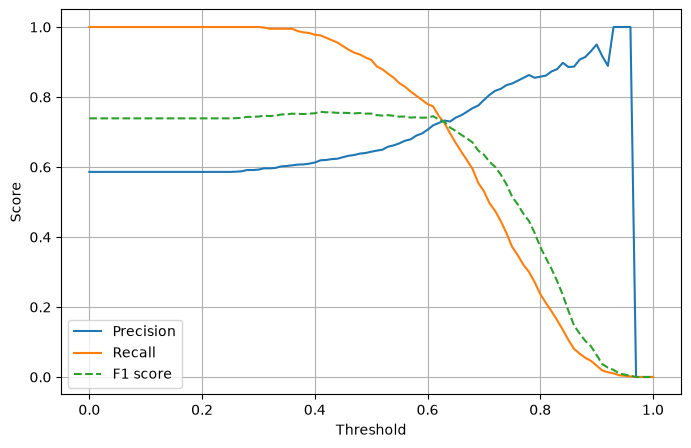

=== QUESTION 3 (Przecięcie Precision i Recall) ===
Threshold: 0.63 (Precision: 0.733, Recall: 0.725)

=== QUESTION 4 (Maksymalne F1) ===
Threshold: 0.41 (Max F1: 0.7576)


In [19]:

thresholds = np.linspace(0.0, 1.0, 101)

scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    
    
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    
    scores.append((t, p, r, abs(p - r), f1))


df_scores = pd.DataFrame(
    scores, 
    columns=['threshold', 'precision', 'recall', 'abs_diff', 'f1']
)


plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.plot(df_scores.threshold, df_scores.f1, label='F1 score', linestyle='--')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.show()


valid_q3 = df_scores[(df_scores['precision'] > 0) & (df_scores['recall'] > 0)]
best_q3 = valid_q3.loc[valid_q3['abs_diff'].idxmin()]

print("=== QUESTION 3 (Przecięcie Precision i Recall) ===")
print(f"Threshold: {best_q3['threshold']:.2f} (Precision: {best_q3['precision']:.3f}, Recall: {best_q3['recall']:.3f})")


best_q4 = df_scores.loc[df_scores['f1'].idxmax()]

print("\n=== QUESTION 4 (Maksymalne F1) ===")
print(f"Threshold: {best_q4['threshold']:.2f} (Max F1: {best_q4['f1']:.4f})")

In [20]:

def train_and_evaluate(df_train_fold, df_val_fold, c=1.0):
    y_train_fold = df_train_fold['converted'].values
    y_val_fold = df_val_fold['converted'].values
    
    train_dicts = df_train_fold.drop(columns=['converted']).to_dict(orient='records')
    val_dicts = df_val_fold.drop(columns=['converted']).to_dict(orient='records')
    
    dv = DictVectorizer(sparse=False)
    X_train_fold = dv.fit_transform(train_dicts)
    X_val_fold = dv.transform(val_dicts)
    
    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
    model.fit(X_train_fold, y_train_fold)
    
    y_pred_fold = model.predict_proba(X_val_fold)[:, 1]
    return roc_auc_score(y_val_fold, y_pred_fold)


kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores_q5 = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]
    
    auc = train_and_evaluate(df_train_fold, df_val_fold, c=1.0)
    scores_q5.append(auc)

print("=== QUESTION 5 ===")
print(f"AUC w poszczególnych foldach: {[round(s, 3) for s in scores_q5]}")
print(f"Odchylenie standardowe (std): {np.std(scores_q5):.3f}\n")

print("=== QUESTION 6 ===")
c_values = [0.000001, 0.001, 1]

for c in c_values:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores_q6 = []
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]
        
        auc = train_and_evaluate(df_train_fold, df_val_fold, c=c)
        scores_q6.append(auc)
        
    mean_auc = round(np.mean(scores_q6), 3)
    std_auc = round(np.std(scores_q6), 3)
    print(f"C = {c:<8} -> mean AUC: {mean_auc:.3f}, std: {std_auc:.3f}")

=== QUESTION 5 ===
AUC w poszczególnych foldach: [0.731, 0.73, 0.736, 0.741, 0.721]
Odchylenie standardowe (std): 0.007

=== QUESTION 6 ===
C = 1e-06    -> mean AUC: 0.617, std: 0.019
C = 0.001    -> mean AUC: 0.749, std: 0.010
C = 1        -> mean AUC: 0.732, std: 0.007
